Data.csv file link: 
https://drive.google.com/file/d/1YUKt2xE1cXEzbzEEDMVZEMdJFIVacG3D/view?usp=sharing

In [192]:
import pandas as pd
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

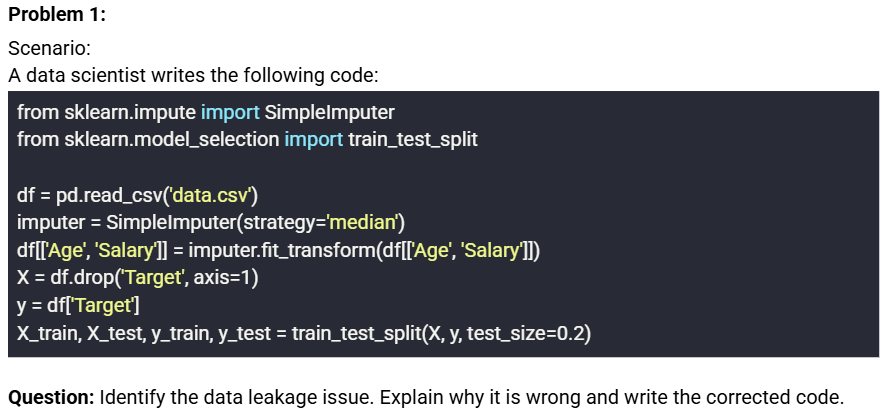

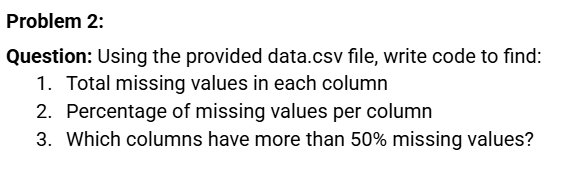

In [188]:
df=pd.read_csv('data.csv')
(df.isnull().mean()*100)[df.isnull().mean()*100>50]

for col,percent in (df.isnull().mean()*100).items():
    if percent>50:
        print(col,percent)

Cabin 68.0


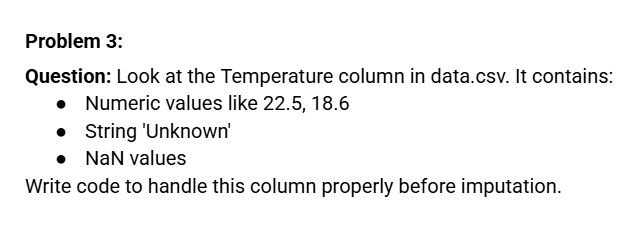

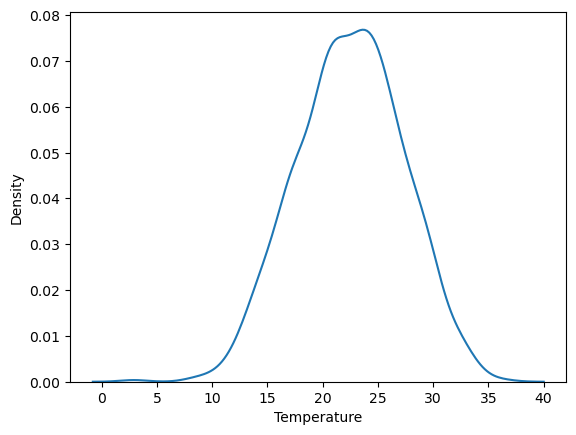

In [189]:


df['Temperature']=pd.to_numeric(df['Temperature'],errors='coerce')
# (errors='coerce') to turn invalid rows into NaN
# df['Temperature']=df['Temperature'].fillna(value=0)
# df['Temperature'].replace({'Unknown':0,pd.NA:0},inplace=True)


# df['Temperature'].isnull().sum()

# df['Temperature'].unique()
# df['Temperature'].dtype

sns.kdeplot(data=df,x='Temperature')

imputer=SimpleImputer(missing_values=pd.NA,strategy='mean')
imputer.fit(df[['Temperature']])
df['Temperature']=imputer.transform(df[['Temperature']]).ravel()


<Axes: xlabel='Temperature', ylabel='Density'>

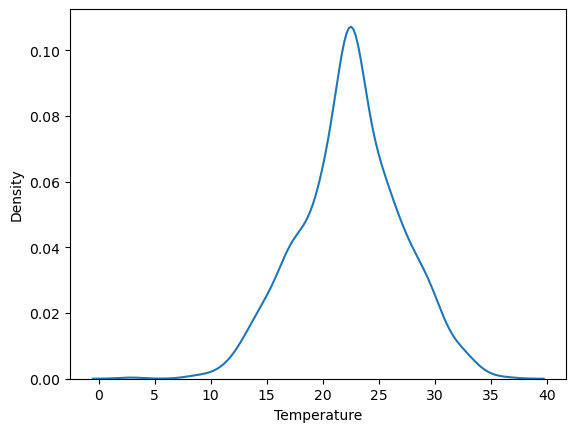

In [190]:
df['Temperature'].sample(10)
sns.kdeplot(data=df,x='Temperature')

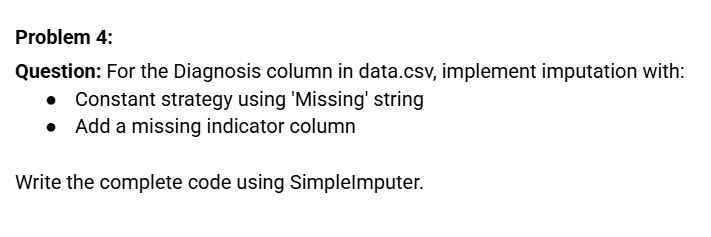

In [191]:
diag_imputer=SimpleImputer(missing_values=pd.NA,strategy="constant",fill_value='Missing',add_indicator=True)
diag_imputer.fit(df[['Diagnosis']])
df[['Diagnosis','Diagnosis_indicator']]=diag_imputer.transform(df[['Diagnosis']])
df['Diagnosis'].isnull().sum()
# df.sample()

np.int64(0)

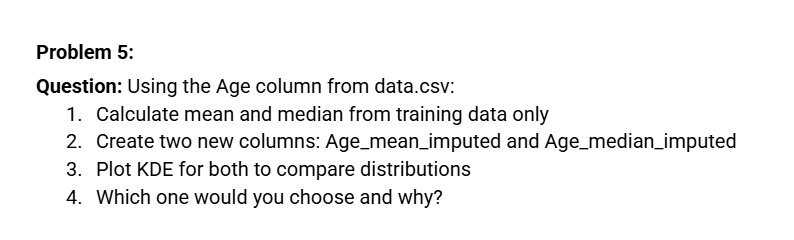

<Axes: xlabel='Age_mean_imputer', ylabel='Density'>

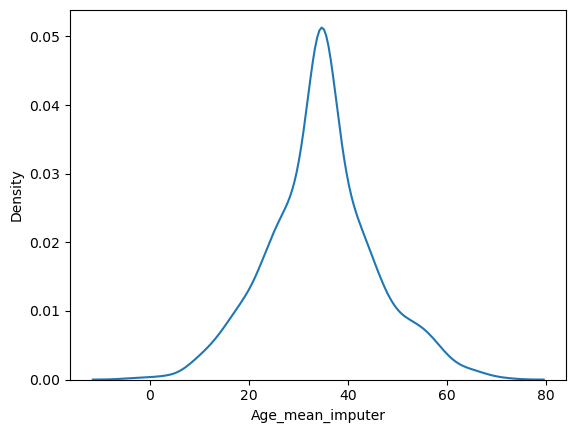

In [208]:
df['Target'].value_counts()
X=df.drop('Target',axis=1)
y=df['Target']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

mean_imputer=SimpleImputer(missing_values=pd.NA,strategy='mean')
mean_imputer.fit(X_train[['Age']])
X_train['Age_mean_imputer']=mean_imputer.transform(X_train[['Age']]).ravel()

median_imputer=SimpleImputer(missing_values=pd.NA,strategy='median')
median_imputer.fit(X_train[['Age']])
X_train['Age_median_imputer']=median_imputer.transform(X_train[['Age']]).ravel()

sns.kdeplot(data=X_train,x='Age_mean_imputer')

<Axes: xlabel='Age_median_imputer', ylabel='Density'>

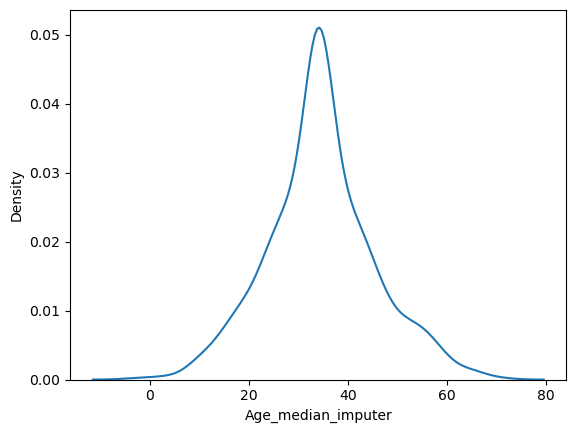

In [209]:
sns.kdeplot(data=X_train,x='Age_median_imputer')

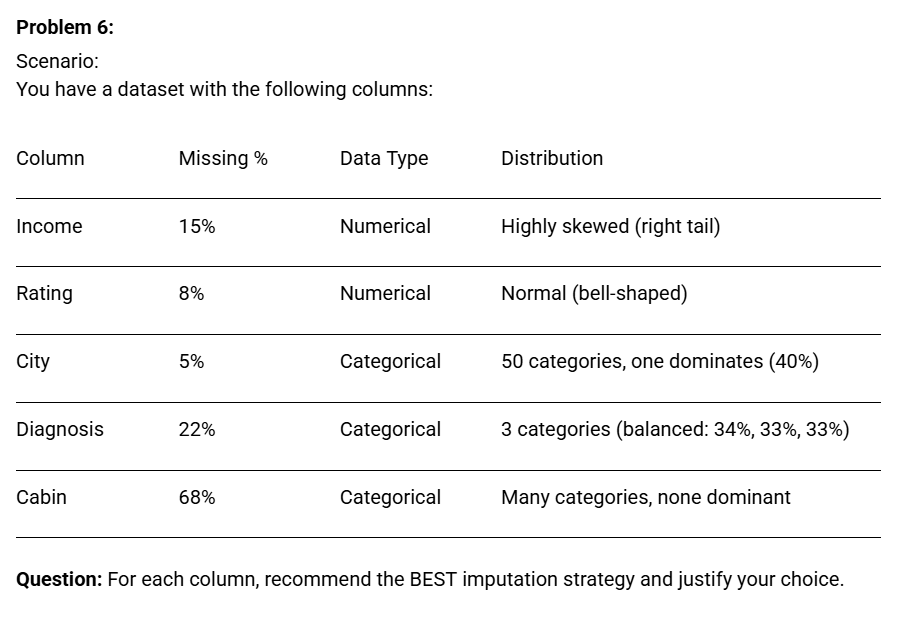